In [94]:
from langgraph.graph import START,END,StateGraph
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage,AIMessage,SystemMessage
from langchain_ollama import ChatOllama
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3
from langchain_core.messages import trim_messages,RemoveMessage
from langchain_core.messages.utils import count_tokens_approximately



In [95]:
llm = ChatOllama(model='qwen2.5:0.5b-instruct',temperature=0.2,max_token=100)

In [96]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage],add_messages]
    summary: str


In [97]:
def chat_node(state:ChatState):
    messages = []
    if state.get('summary',''):
        messages.append(SystemMessage(content=state['summary']))
    messages.extend(state['messages'])
    print("for LLM ====>",messages)
    res = llm.invoke(messages)
    return {'messages':[res]}

def delete_old_messages(state:ChatState):
    existing_summary = state.get('summary','')
    messages = state.get('messages',[])
    if existing_summary: 
        prompt = f"""Existing summary : {existing_summary}
                    Extend the summary using the new conversation above."""
    else : 
        prompt = "Summarize the above conversation."
    messages_for_summary = messages + [HumanMessage(content=prompt)]
    new_summary = llm.invoke(messages_for_summary)
    to_remove = messages[:5]                    # delete first 5 messages
    return {'messages':[RemoveMessage(id=m.id) for m in to_remove],'summary':new_summary.content}

def cleanup_condition(state:ChatState):
    messages = state['messages']
    if len(messages) > 10:
        return 'cleanup'
    return END

    

In [98]:
graph = StateGraph(ChatState)

graph.add_node('chat_node',chat_node)
graph.add_node('cleanup',delete_old_messages)

graph.add_edge(START,'chat_node')
graph.add_conditional_edges('chat_node',cleanup_condition,{'cleanup':'cleanup',END:END})
graph.add_edge('cleanup',END)

conn = sqlite3.connect('database/store.db',check_same_thread=False)
chatbot = graph.compile(checkpointer=SqliteSaver(conn=conn))


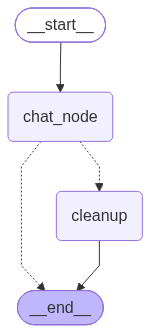

In [99]:
chatbot

In [100]:
# thread_id = '2'
# while True:
#     user_message = input("Ask anything: ")
#     print("Human : ",user_message)

#     if user_message.strip().lower() in ['exit','bye','quit']:
#         break

#     config = {'configurable':{'thread_id':thread_id}}
#     res = chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)

#     print('AI : ',res['messages'][-1].content)

In [101]:
def show_state(config):
    res = chatbot.get_state(config=config).values
    print(res)
    print('count of messages : ',len(res.get('messages','')))
    print('summary : ',res.get('summary',''))

In [103]:
config = {'configurable':{'thread_id':'thread1'}}
chatbot.invoke({'messages':[HumanMessage(content="I am a user my name is  girish")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="what is gb and tb")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="how are you doing")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="tell me a joke")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="what is mean by manhole")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="what is google")]},config=config)
show_state(config)
chatbot.invoke({'messages':[HumanMessage(content="what is my name")]},config=config)
show_state(config)

for LLM ====> [HumanMessage(content='I am a user my name is  girish', additional_kwargs={}, response_metadata={}, id='0916c851-b897-46ff-a485-e90af8d34b20')]
{'messages': [HumanMessage(content='I am a user my name is  girish', additional_kwargs={}, response_metadata={}, id='0916c851-b897-46ff-a485-e90af8d34b20'), AIMessage(content="Hello Girish! It's nice to meet you. How can I assist you today? If you have any questions or need help with something specific, feel free to ask. I'm here to help and provide information on various topics.", additional_kwargs={}, response_metadata={'model': 'qwen2.5:0.5b-instruct', 'created_at': '2026-09-21T17:59:02.563223779Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1170780067, 'load_duration': 201415346, 'prompt_eval_count': 39, 'prompt_eval_duration': 94913000, 'eval_count': 48, 'eval_duration': 868751000, 'logprobs': None, 'model_name': 'qwen2.5:0.5b-instruct', 'model_provider': 'ollama'}, id='lc_run--01a0c51f-0c0f-7ff0-8966-90d8b0a93810

In [75]:
def show_state():
    res = chatbot.get_state(config=config)
    print('count of messages : ',len(res['messages']))
    print('summary : ',res['summary'])

In [68]:
res = chatbot.invoke({'messages':[HumanMessage(content="what is my name")]},config=config)

[SystemMessage(content='The conversation between Qwen and a user about the meaning of "manhole" is as follows:\n\nQwen: Hello! How are you today?\nUser: I\'m doing well, thanks.\nQwen: Is there anything specific you\'d like to know or discuss?', additional_kwargs={}, response_metadata={})]
for LLM ====> [SystemMessage(content='The conversation between Qwen and a user about the meaning of "manhole" is as follows:\n\nQwen: Hello! How are you today?\nUser: I\'m doing well, thanks.\nQwen: Is there anything specific you\'d like to know or discuss?', additional_kwargs={}, response_metadata={}), AIMessage(content="As an AI language model, I don't have feelings or emotions in the same way that humans do. However, I'm always ready to help and answer your questions! How can I assist you today?", additional_kwargs={}, response_metadata={'model': 'qwen2.5:0.5b-instruct', 'created_at': '2026-09-21T17:46:34.74330521Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1021021225, 'load_duration

In [69]:
print(res['messages'][-1])

content='Your name is Qwen. It\'s a popular Chinese word that means "man" in English.' additional_kwargs={} response_metadata={'model': 'qwen2.5:0.5b-instruct', 'created_at': '2026-09-21T17:46:45.77429557Z', 'done': True, 'done_reason': 'stop', 'total_duration': 830992192, 'load_duration': 257836245, 'prompt_eval_count': 433, 'prompt_eval_duration': 129428000, 'eval_count': 21, 'eval_duration': 434925000, 'logprobs': None, 'model_name': 'qwen2.5:0.5b-instruct', 'model_provider': 'ollama'} id='lc_run--01a0c513-cf4e-7152-8724-edcd902f7c9a-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 433, 'output_tokens': 21, 'total_tokens': 454}
